# Generalized script to determine the eigenvalues, eigenvectors and the dipole moments of a selected network graph

- This script will be able to calculate the specific features from the adjacency matrix imported from (https://houseofgraphs.org/)

In [37]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.linalg import eig, expm

matrix_A = np.loadtxt("graph_26_adjacency_matrix.txt", dtype=int)
print(type(matrix_A))
print(matrix_A)

<class 'numpy.ndarray'>
[[0 1 1 0 0 1 1]
 [1 0 0 1 0 1 1]
 [1 0 0 0 1 1 1]
 [0 1 0 0 1 1 1]
 [0 0 1 1 0 1 1]
 [1 1 1 1 1 0 1]
 [1 1 1 1 1 1 0]]


### Calculataing the eigenvalues, DOS and eigenvectors 

In [38]:
matrix_A = np.loadtxt("graph_26_adjacency_matrix.txt", dtype=int)
N = matrix_A.shape[0]
print("Diagonal elements:", N)
eigenvalues, eigenvectors = np.linalg.eigh(matrix_A)
print("eigenvalues:", np.round(eigenvalues, 2))

# Grouping the eigenvalues and finding their multiplicities and DOS
mu, m = np.unique(np.round(eigenvalues, 2), return_counts=True)
w = m / N                                    # DOS weight for each eigenvalue

for x, k, p in zip(mu, m, w):
    print(f"lambda = {x:.1f}   multiplicity = {k}   DOS = {p:.2f}")

print("Eigenvectors:", np.round(eigenvectors, 2))

Diagonal elements: 7
eigenvalues: [-1.7  -1.62 -1.62 -1.    0.62  0.62  4.7 ]
lambda = -1.7   multiplicity = 1   DOS = 0.14
lambda = -1.6   multiplicity = 2   DOS = 0.29
lambda = -1.0   multiplicity = 1   DOS = 0.14
lambda = 0.6   multiplicity = 2   DOS = 0.29
lambda = 4.7   multiplicity = 1   DOS = 0.14
Eigenvectors: [[ 0.29 -0.03  0.63  0.   -0.03  0.63 -0.34]
 [ 0.29 -0.35 -0.53 -0.    0.59  0.22 -0.34]
 [ 0.29  0.39 -0.5   0.   -0.61  0.17 -0.34]
 [ 0.29  0.59  0.22  0.    0.39 -0.5  -0.34]
 [ 0.29 -0.61  0.17 -0.   -0.35 -0.53 -0.34]
 [-0.54  0.   -0.    0.71  0.   -0.   -0.46]
 [-0.54  0.   -0.   -0.71 -0.   -0.   -0.46]]


### Sampling random numbers along the diagonal
- The mean is 0 because of bare transition energy, hw0 = 0 for all emitters. Seed ensures that we get the same randomization across all tries. 
- The mean of the final result =/ 0, because the sample is too small. To check if the distrubution is accurate, increase the number of sampling and check whether mean and std dev lies where expected 

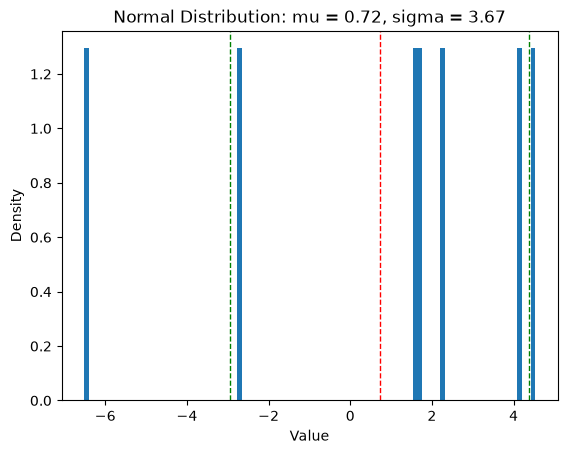

array([ 1.72792096,  4.10809072,  1.65218538, -6.51578616,  4.52677933,
        2.23187286, -2.68476618])

In [39]:
elements = len(matrix_A) # gives the number of rows in the matrix

# initializing random number generator 
seed = 1
rng = np.random.default_rng(seed)
mean = 0 
std = 5               

sample = rng.normal(mean, std, elements) # generates a sample of random numbers from a normal distribution
plt.hist(sample, bins=100, density=True);
mu0, sigma0 = np.mean(sample), np.std(sample)
plt.axvline(mu0, color='r', linestyle='dashed', linewidth=1)
plt.axvline(mu0 + sigma0, color='g', linestyle='dashed', linewidth=1)
plt.axvline(mu0 - sigma0, color='g', linestyle='dashed', linewidth=1)
plt.title(f"Normal Distribution: mu = {mu0:.2f}, sigma = {sigma0:.2f}")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()
sample

### Adding the numbers to the diagonal matrix
NOTE - Setting the cavity indices to 0 will have to be done manually across different network topologies since the number and position of cavities vary across topologies

Text(0.5, 1.0, 'Diagonal matrix with disorder and cavity indices set to 0')

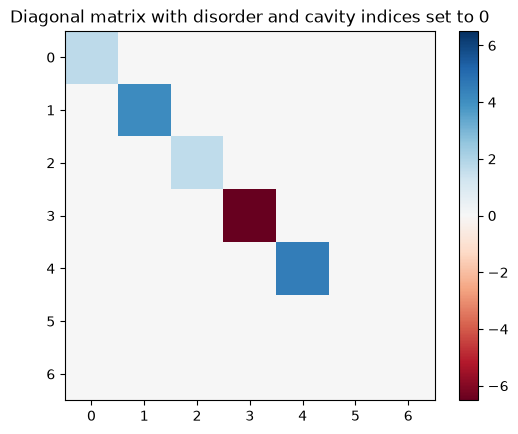

In [40]:
# create a diagonal matrix with the random numbers on the diagonal
matrix_D = np.diag(sample)

# cavity indices
c_ind = [5,6]

# replace the elements of the diagonal matrix with the cavity indices with 0
matrix_D[c_ind, c_ind] = 0
plt.imshow(matrix_D, cmap='RdBu', vmin=-np.max(np.abs(matrix_D)), vmax=np.max(np.abs(matrix_D)))
# plot the colorbar
plt.colorbar();
plt.title("Diagonal matrix with disorder and cavity indices set to 0")

## Spectrum of system with disorder

#### Calculation of eigenvalues and eigenvectors for the disordered system

In [41]:
eigenvalues_dis, eigenvectors_dis = np.linalg.eigh(matrix_A+matrix_D)
print("Eigenvectors:", np.round(eigenvectors_dis, 2))
print("eigenvalues:", np.round(eigenvalues_dis, 2))

# Grouping the eigenvalues and finding their multiplicities and DOS
mu, m = np.unique(np.round(eigenvalues_dis, 2), return_counts=True)
w = m / N                                    # DOS weight for each eigenvalue

for x, k, p in zip(mu, m, w):
    print(f"lambda = {x:.1f}   multiplicity = {k}   DOS = {p:.2f}")

Eigenvectors: [[ 0.03  0.    0.28  0.69  0.54 -0.23 -0.31]
 [-0.07  0.    0.22 -0.17 -0.46 -0.7  -0.47]
 [ 0.03 -0.    0.33 -0.68  0.56  0.12 -0.32]
 [ 0.98  0.   -0.13 -0.01 -0.06 -0.01 -0.13]
 [-0.07 -0.    0.2   0.18 -0.38  0.67 -0.58]
 [-0.11 -0.71 -0.59 -0.02  0.14 -0.04 -0.33]
 [-0.11  0.71 -0.59 -0.02  0.14 -0.04 -0.33]]
eigenvalues: [-6.89 -1.   -0.52  0.43  2.45  4.57  6.46]
lambda = -6.9   multiplicity = 1   DOS = 0.14
lambda = -1.0   multiplicity = 1   DOS = 0.14
lambda = -0.5   multiplicity = 1   DOS = 0.14
lambda = 0.4   multiplicity = 1   DOS = 0.14
lambda = 2.5   multiplicity = 1   DOS = 0.14
lambda = 4.6   multiplicity = 1   DOS = 0.14
lambda = 6.5   multiplicity = 1   DOS = 0.14


#### Defining the function for the brightness calculation
Here I changed the function bec we already define the adjacency matrix and the cavity indices in the main code, 
so we don't need to pass them as arguments again

In [42]:
def bright_states(H, dips, tol=1e-8, d0=1.0):
    # eigenstates of the Hermitian H (columns of C) and their transition dipoles D_k = sum_m c_m^(k) d_m
    E, C = np.linalg.eigh(H)
    i = 0
    while i < len(E):                                                   # find blocks of equal energy
        j = i + 1
        while j < len(E) and E[j] - E[i] < tol:
            j += 1
        if j - i > 1:                                                   # rotate the block: at most 3 bright states
            _, _, Vh = np.linalg.svd(dips.T @ C[:, i:j])
            C[:, i:j] = C[:, i:j] @ Vh.conj().T
        i = j
    D = C.T @ dips                                                      # row k is D_k
    B = np.sum(np.abs(D) ** 2, axis=1) / d0 ** 2                        # brightness B_k = |D_k|^2 / d0^2
    return E, C, D, B
 
def graph26(adj, cav, dipoles, energies, g, field_c, J=1.0, d0=1.0):
    adj = np.asarray(adj, dtype=float)
    n = len(adj)
    cav = list(cav)
    emitters = [k for k in range(n) if k not in cav]
    energies = np.asarray(energies, dtype=float)

    # check inputs
    assert energies.ndim == 1 and len(energies) == n,  "energies must be a 1D array, one per node"
    assert len(dipoles) == len(emitters),              "need one dipole per emitter node"

    all_dips = np.zeros((n, 3))
    all_dips[emitters] = dipoles

    gm = g * all_dips @ field_c / d0

    H = J * adj
    for c in cav:
        for m in emitters:
            if adj[c, m]:
                H[c, m] = H[m, c] = gm[m]
    H += np.diag(energies)
    return H, all_dips

def graph26_analytic(dipoles, g, field_c, d0=1.0):
    gm = g * dipoles @ field_c / d0
    G = np.linalg.norm(gm)
    if G == 0:
        raise ValueError("no emitter couples to the cavity (G = 0)")
    B_pol = np.linalg.norm(gm @ dipoles) ** 2 / (2 * G ** 2 * d0 ** 2)
    return np.array([-G, 0, G]), np.array([B_pol, np.sum(dipoles ** 2) / d0 ** 2 - 2 * B_pol, B_pol])

Number of bright states: 6
Number of dark states: 1


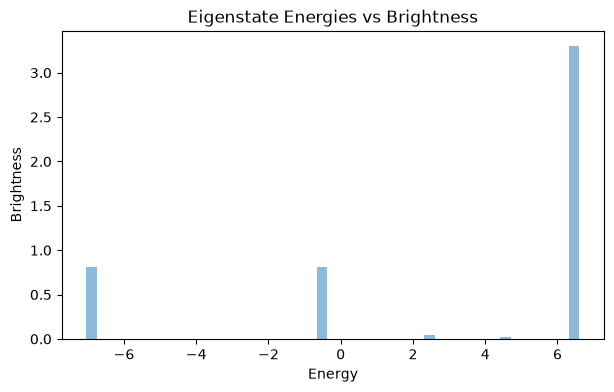

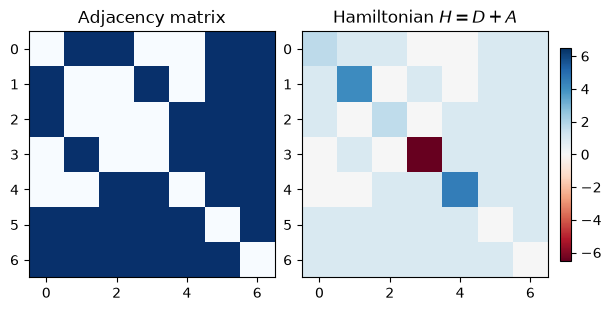

In [43]:
c_ind = [5, 6]                                                             # Define the indices that are the cavity nodes
N = len(matrix_A) - len(c_ind)                                             # number of emitters

# dipole parameters
g = 1.0                                               # cavity coupling of a dipole d0 along e_c (energy unit)
field_c = np.array([1.0, 0, 0])                       # cavity field polarisation
dipoles = np.array([[1.0, 0, 0] for _ in range(N)])   # identical dipoles along e_c

# energy landscape                                                       # 5 emitters if c_ind = [5, 6]
energies = np.where(np.isin(np.arange(len(sample)), c_ind), 0, sample)   # 1D vector: no np.diag                           # energies: cavity first, then emitters

# get the adjacency matrix of the star graph and the dipoles of the cavity and emitters
A = matrix_A
H, all_dipoles = graph26(matrix_A, c_ind, dipoles, energies, g, field_c)

# get the energies, eigenstates, transition dipoles and brightness of the eigenstates
E, C, D, B = bright_states(H, all_dipoles)

# print the amount of bright states and of dark states
print(f'Number of bright states: {np.sum(B > 1e-8)}')
print(f'Number of dark states: {np.sum(B < 1e-8)}')

# plot the energies and brightness of the eigenstates
plt.figure(figsize=(7, 4))
plt.bar(E, B, width=0.3, color='C0', alpha=0.5)
plt.title('Eigenstate Energies vs Brightness')
plt.xlabel('Energy')
plt.ylabel('Brightness');

# plot the adjecency matrix of the star graph
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3), layout="constrained")

ax1.imshow(matrix_A, cmap='Blues', interpolation='nearest')
ax1.set_title('Adjacency matrix')

vmax = np.max(np.abs(H))
im = ax2.imshow(H, cmap='RdBu', vmin=-vmax, vmax=vmax, interpolation='nearest')
ax2.set_title('Hamiltonian $H = D + A$')
fig.colorbar(im, ax=ax2, shrink=0.8)

plt.show()

In [44]:
C.T[0]

array([ 0.03120585, -0.07119157,  0.03117272,  0.98085214, -0.06857825,
       -0.11448215, -0.11448215])

In [45]:
vec = np.array([10,10,10,10,10,0,0])
vec = vec / np.linalg.norm(vec)
vec

array([0.4472136, 0.4472136, 0.4472136, 0.4472136, 0.4472136, 0.       ,
       0.       ])

### Yield

The system starts with one excitation in the cavity, $\psi_0=e_0$. We compute $\phi_s$ in three independent ways and compare them at the end.

**1. Time integral.** Propagate $\psi(t)=e^{-iH_{\rm eff}t}\psi_0$ and integrate the sink flux $\psi^\dagger K_s\psi$.

In [46]:
# radiative emission rate (loss) of the cavity only
kappa = 0.1
d0 = 1.0

# collective electron transfer rate (useful extraction) from the bright state of the emitters
Gamma = 0.2

n = len(H) 
# compose anti-Hermitian matrix K
K_rad = np.diag([kappa*(k in c_ind) for k in range(n)]) ## this is for the cavities only
K_sink = np.diag([Gamma*(k not in c_ind) for k in range(n)]) ## this is for the emitters only

# total anti-Hermitian matrix K = K_rad + K_s
K = K_rad + K_sink

# effective non-Hermitian Hamiltonian H_eff = H - i/2 K
H_eff = H - 0.5j * K      

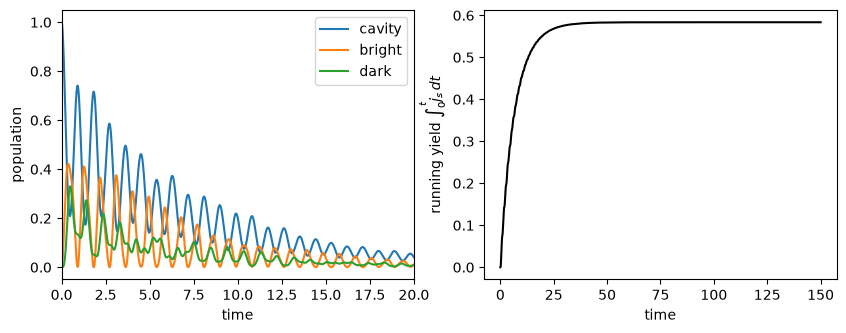

In [47]:
# node bookkeeping
n_nodes = len(H)                                           # 7 for graph 26 
emitters = [k for k in range(n_nodes) if k not in c_ind]   # excluding the cavity nodes from list of nodes 

# initial state: one excitation in cavity node 5 or 6
psi0 = np.eye(n_nodes)[:, c_ind[0]] + np.eye(n_nodes)[:, c_ind[1]]
psi0 /= np.linalg.norm(psi0)  # normalizing the probability for cavity excitation

# propagate psi(t) with a fixed time step
t = np.linspace(0, 150, 15001)
U = expm(-1j * H_eff * (t[1] - t[0]))   # what is operator U? Hint: unitary evolution operator 
psi = np.empty((len(t), n_nodes), complex)
psi[0] = psi0
for k in range(1, len(t)):
    psi[k] = U @ psi[k - 1]   

# sink flux and its time integral
j_s = np.einsum('ti,ij,tj->t', psi.conj(), K_sink, psi).real
phi_time = np.trapezoid(j_s, t)

# bright state: emitter combination that couples to the cavity (zero on cavity nodes)
gm = g * all_dipoles @ field_c / d0
b = gm / np.linalg.norm(gm)

# populations of the cavities, of the bright state and of the dark states
p_c = np.sum(np.abs(psi[:, c_ind]) ** 2, axis=1)
p_b = np.abs(psi @ b.conj()) ** 2
p_d = np.sum(np.abs(psi[:, emitters]) ** 2, axis=1) - p_b

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(t, p_c, label='cavity')
axs[0].plot(t, p_b, label='bright')
axs[0].plot(t, p_d, label='dark')
axs[0].set(xlabel='time', ylabel='population', xlim=(0, 20))
axs[0].legend()
axs[1].plot(t, np.cumsum(j_s) * (t[1] - t[0]), color='k')
axs[1].set(xlabel='time', ylabel=r'running yield $\int_0^t j_s\,dt$');

**2. Steady state.** The time-integrated state $M=\int_0^\infty\psi\psi^\dagger dt$ is the steady state under a constant injection of $\psi_0$. It solves $H_{\rm eff}M-MH_{\rm eff}^\dagger=-i\psi_0\psi_0^\dagger$, and $\phi_s={\rm Tr}(K_sM)$. The dark states never decay, so this equation is singular. Since $\psi_0$ has no dark component, the least-squares solution is the physical one.

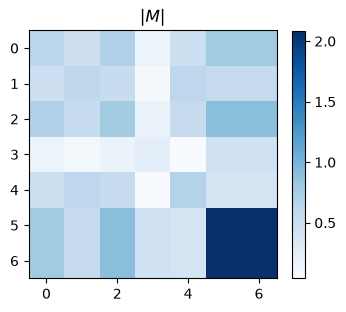

In [48]:
# vectorised equation (columns of M stacked): (I x H_eff - H_eff^* x I) vec(M) = -i vec(psi0 psi0^dagger)
I = np.eye(N + 1)
L = np.kron(I, H_eff) - np.kron(H_eff.conj(), I)
In = np.eye(n_nodes)
L = np.kron(In, H_eff) - np.kron(H_eff.conj(), In)
b_ss = -1j * np.outer(psi0, psi0.conj()).ravel(order='F')
M = np.linalg.lstsq(L, b_ss, rcond=None)[0].reshape(n_nodes, n_nodes, order='F')

phi_ss = np.trace(K_sink @ M).real

plt.figure(figsize=(4, 4))
plt.imshow(np.abs(M), cmap='Blues', interpolation='nearest')
plt.colorbar(shrink=0.8)
plt.title(r'$|M|$');

**3. Spectral method.** Write $H_{\rm eff}=\sum_k\mu_k\,r_kl_k$ with right and left eigenvectors normalised so that $l_kr_k=1$. The initial state excites mode $k$ with amplitude $c_k=l_k\psi_0$, so $\psi(t)=\sum_kc_ke^{-i\mu_kt}r_k$, and the time integral gives
$$\phi_s=\sum_{k,l}\frac{c_k\,c_l^*\,(r_l^\dagger K_s r_k)}{i(\mu_k-\mu_l^*)} .$$
Only modes with $c_k\neq0$ contribute (the dark modes have $\mu_k=0$ and $c_k=0$).

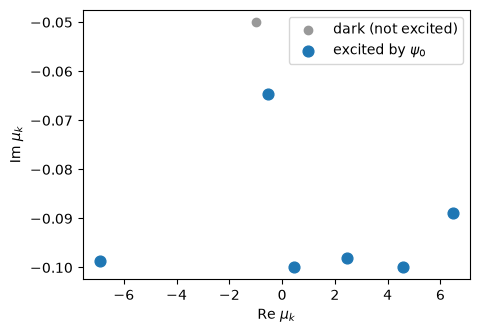

In [49]:
# eigenvalues and left/right eigenvectors of H_eff, normalised so that l_k r_k = 1
mu, l, r = eig(H_eff, left=True)
l = l.conj() / np.sum(l.conj() * r, 0)

# amplitudes c_k = l_k psi0, keep only the excited modes
c = l.T @ psi0
on = np.abs(c) > 1e-10
mu_on, c_on, r_on = mu[on], c[on], r[:, on]

# double sum over the excited modes
Kr = r_on.conj().T @ K_sink @ r_on                        # Kr[l, k] = r_l^dagger K_s r_k
phi_spec = np.sum(np.outer(c_on, c_on.conj()) * Kr.T / (1j * (mu_on[:, None] - mu_on.conj()[None, :]))).real

plt.figure(figsize=(5, 3.5))
plt.scatter(mu.real[~on], mu.imag[~on], color='0.6', label='dark (not excited)')
plt.scatter(mu.real[on], mu.imag[on], s=60, color='C0', label=r'excited by $\psi_0$')
plt.xlabel(r'Re $\mu_k$')
plt.ylabel(r'Im $\mu_k$')
plt.legend();

### Check and comparison

The cavity talks only to the bright state, with collective coupling $G=\sqrt N g$, so the problem reduces to two levels. For two resonant levels the yield is $\phi_s=4G^2\Gamma/\big((k_{\rm rad}+\Gamma)(4G^2+k_{\rm rad}\Gamma)\big)$. The excitation leaves through either the sink or the cavity, so $\phi_s+\phi_{\rm rad}=1$ with $\phi_{\rm rad}={\rm Tr}(K_{\rm rad}M)$.

phi_exact = 0.6658
phi_s + phi_rad = 1.000000
max dark population = 3.3e-01
 time integral: phi_s = 0.583513   error = -8.2e-02
  steady state: phi_s = 0.583513   error = -8.2e-02
      spectral: phi_s = 0.583513   error = -8.2e-02


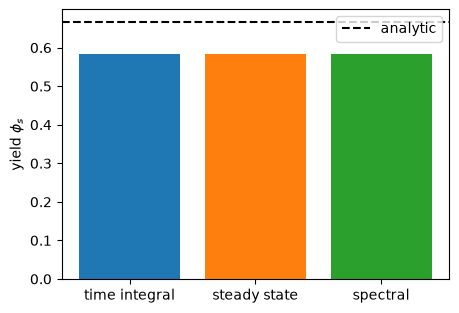

In [50]:
# analytic two-level result
G = np.linalg.norm(A[0, 1:])
phi_exact = 4 * G ** 2 * Gamma / ((kappa + Gamma) * (4 * G ** 2 + kappa * Gamma))
print(f'phi_exact = {phi_exact:.4f}')

# yield into the radiative channel and conservation of probability
phi_rad = np.trace(K_rad @ M).real
print(f'phi_s + phi_rad = {phi_ss + phi_rad:.6f}')
print(f'max dark population = {p_d.max():.1e}')

# compare the three methods with the analytic result
methods = {'time integral': phi_time, 'steady state': phi_ss, 'spectral': phi_spec}
for name, phi in methods.items():
    print(f'{name:>14}: phi_s = {phi:.6f}   error = {phi - phi_exact:+.1e}')

plt.figure(figsize=(5, 3.5))
plt.bar(methods.keys(), methods.values(), color=['C0', 'C1', 'C2'], alpha=1.0)
plt.axhline(phi_exact, color='k', ls='--', label='analytic')
plt.ylabel(r'yield $\phi_s$')
plt.legend(loc='upper right');